In [1]:
import sys
sys.path.append("../")

from config import *
from figs_config import *

from interpmodules import helpers

Loaded aesthetics module


* __R1C1:__ \
Variogram models for empirical brain maps (Fig. S4A). It is counter-intuitive that more complex variogram models, stable and matern, provide consistently worse (worst) fit (larger MAE) relative to simpler models, in particular for those maps where the exponential variogram model was the best. This is because stable and matern models can fit the exponential curve under certain parameters. The authors may want to check their code at https://github.com/netneurolab/zhou_interpolates/blob/main/code/res2_neuromaps_full.ipynb, cell 141, particularly the shape parameter bound condition for model optimization. In addition, I recommend that upper bounds for other parameters should allow range > max(h), sill > max(ev), and a more flexible nugget, because extremely distant data in the map may remain related and measurement noise can be large. The fitting curves displayed in the notebook suggest that almost all variogram models are negatively impacted by the parameter bounds used.

In [2]:
import joblib
import pandas as pd

src_pvdata = joblib.load( projdir + '/data/fsLR-4k_reduced-midthickness_neuromaps.pkl')

maptags = pd.read_table(projdir + '/data/surf_map_names', delimiter = " ", dtype = str)
maptags = list(maptags.columns)

In [3]:
corder = ['gene expression', 'MEG', 'structural', 'functional', 'metabolism', 'expansion']
ccolours = [
    to_hex(plt.cm.terrain(0.2)),  # gene: light turquoise
    to_hex(plt.cm.spring(0.65)),  # MEG: orange
    to_hex(plt.cm.cubehelix(0.7)),  # structural: violet
    to_hex(plt.cm.terrain(0.3)),  # functional: green
    to_hex(plt.cm.nipy_spectral(0.3)), # metabolism: blue
    to_hex(plt.cm.spring(0.37)) # expansion: pink
]

cpal = dict(zip(corder, ccolours))
sns.color_palette(ccolours)

[(0.0, 0.6980392156862745, 0.6980392156862745),
 (1.0, 0.6509803921568628, 0.34901960784313724),
 (0.8117647058823529, 0.615686274509804, 0.8588235294117647),
 (0.19215686274509805, 0.8392156862745098, 0.4392156862745098),
 (0.0, 0.596078431372549, 0.8666666666666667),
 (1.0, 0.3686274509803922, 0.6313725490196078)]

In [4]:
Dist = helpers.internal_distance_matrix(src_pvdata.points, 'euclidean')

In [6]:
import joblib
mapnames, h, all_ev = joblib.load( '/home/yzhou/gitrepo/interpolate/results/stats/neuromaps_collected_expvgm.pkl' )

In [7]:
import gstools as gs
import skgstat as skg
skgstat_mdls = {'spherical': skg.models.spherical, 
                'exponential': skg.models.exponential,
                'gaussian': skg.models.gaussian,
                'cubic': skg.models.cubic,
                'stable': skg.models.stable,
                'matern': skg.models.matern,
               'hole': helpers.hole}

In [8]:
def semivariance(y1, y2):
    return .5 * (y1 - y2)**2

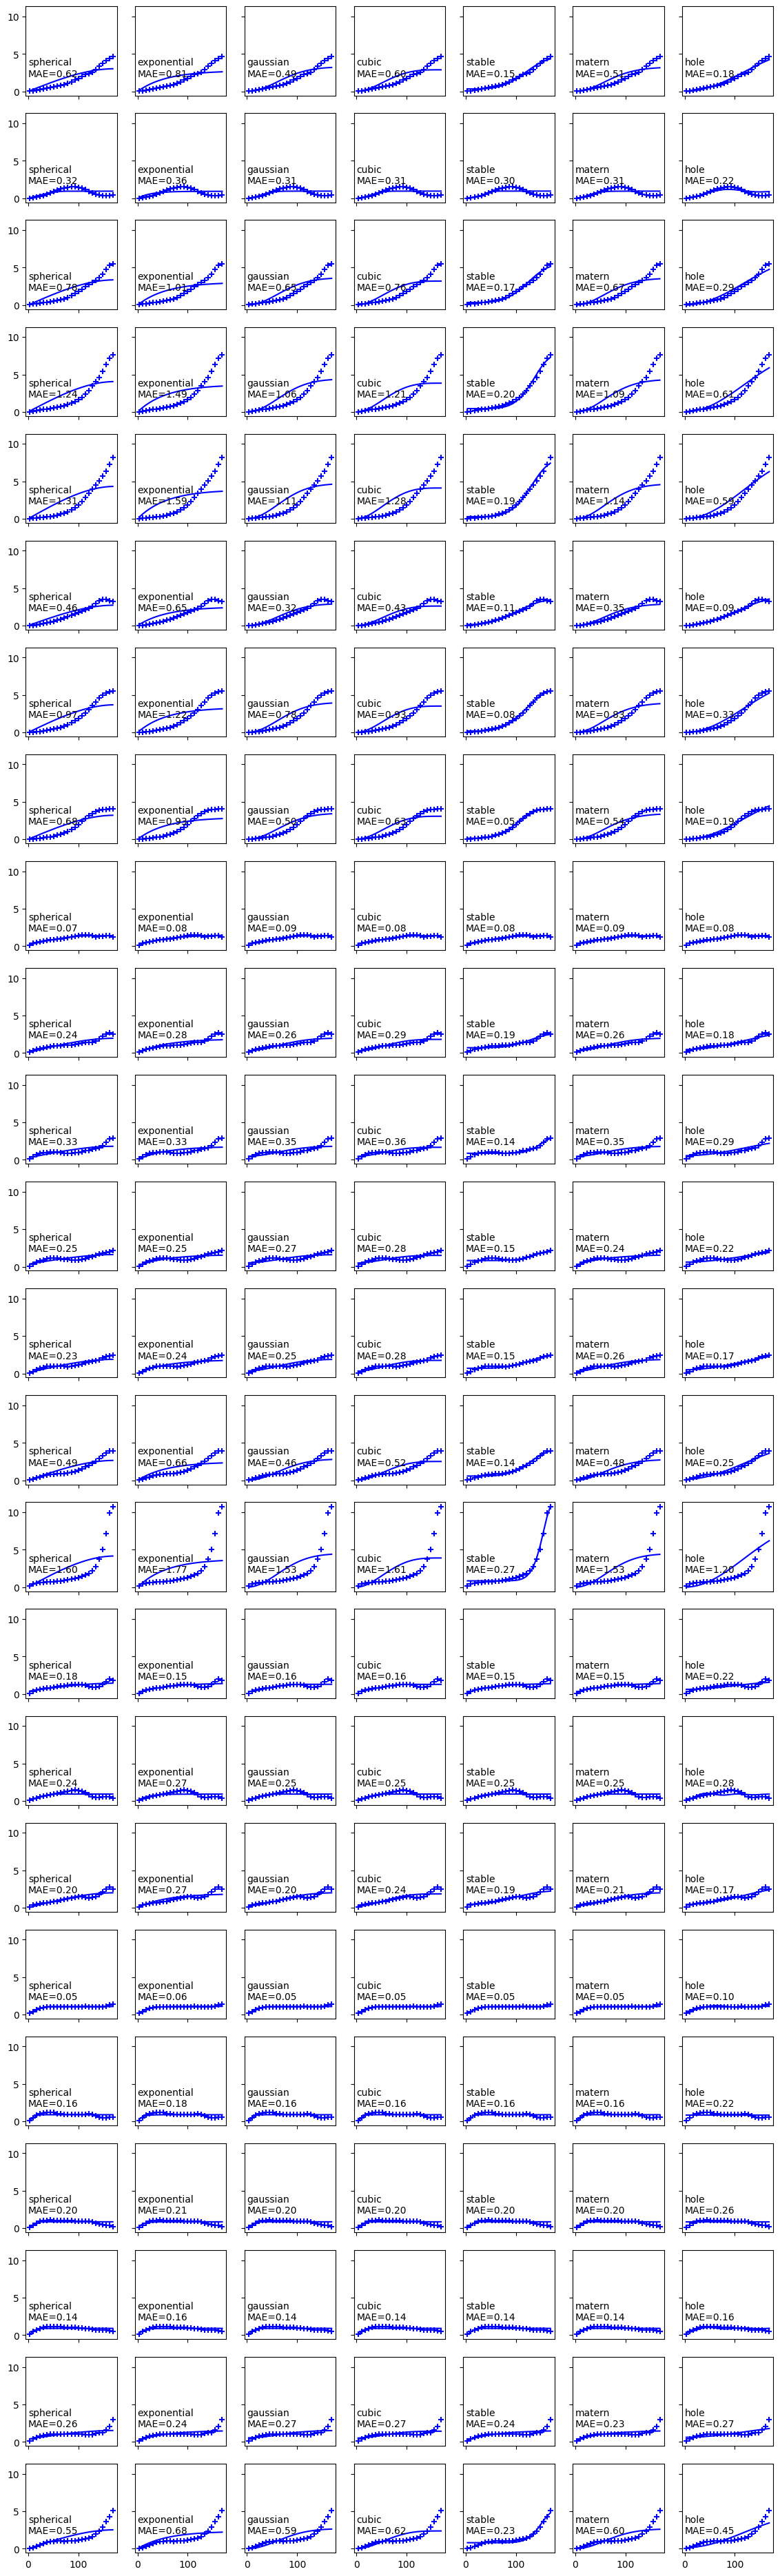

In [19]:
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics

fig, axs = plt.subplots(24,7, figsize = (14,48), sharex=True,sharey=True)

model_scores = {}

for mi, mapname in enumerate(mapnames):
    ev = all_ev[:,mi]
    nh = 25
    
    p0 = {3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
              4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
             }

    mapvals = zscore(src_pvdata[mapname])
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}
    
    cof = None; cov = None
    
    gof = {}
    
    for ind, model in enumerate(skgstat_mdls):
    
        axs[mi,ind].scatter(h, ev, marker = "+", color = 'b')
        
        
        if model in ['stable', 'matern']:
            cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[4], bounds = bounds[4], maxfev=1000)
        
        else:
            cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = p0[3], bounds = bounds[3], maxfev=1000)

        
        v_pred = skgstat_mdls[model](h, *cof)
        x_s = np.linspace(h.min(), h.max())
        axs[mi, ind].plot(h, v_pred, color = 'b')
        mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
        r2 = r2_score(ev, v_pred)
        gof[model] = r2
        
        axs[mi, ind].text(x=0, y=2,s= model + "\n" + r'MAE=' + '{0:.2f}'.format(mae))

    model_scores[mapname] = gof

In [26]:
import numpy as np

matrix = np.zeros((7, 24))

for mi, mapname in enumerate(maptags):
    matrix[:, mi] = pd.DataFrame( model_scores[mapname].values(), model_scores[mapname].keys() )[0].to_numpy()

In [36]:
extended_cpal = {}

from interpmodules import helpers

global_i_s = pd.DataFrame(index = maptags, columns = ['i'])

Dist = helpers.internal_distance_matrix(src_pvdata.points, 'euclidean')

for maptag in maptags:
    global_i = helpers.morans_i(Dist, src_pvdata[maptag], normalize=True)
    global_i_s.loc[maptag] = global_i

cat = []

maptocat = {'gene expression': ['abagen_genepc1'], \
            'MEG': ['hcps1200_meg' + fband for fband in fbands ] + ['hcps1200_megtimescale'], \
            'structural': ['hcps1200_thickness', 'hcps1200_myelinmap'], \
            'functional': ['margulies2016_fcgradient01', 'mueller2013_intersubjvar', 'xu2020_FChomology', 'sydnor2021_SAaxis'], \
            'metabolism': ['raichle_cbf', 'raichle_cbv', 'raichle_cmr02', 'raichle_cmrglc'], \
            'expansion': ['hill2010_devexp', 'hill2010_evoexp', 'xu2020_evoexp', 'reardon2018_scalinghcp', 'reardon2018_scalingnih', 'reardon2018_scalingpnc']}


for row in range(len(global_i_s)):
    for category in maptocat:
        if global_i_s.index[row] in maptocat[category]:
            cat.append( category )
        else: continue

global_i_s['category'] = cat


for maptag in mapnames:
    extended_cpal[maptag] = cpal[global_i_s.loc[maptag]['category']]

In [50]:
data = pd.DataFrame(matrix)
dir(data.columns)

['T',
 '__abs__',
 '__add__',
 '__and__',
 '__annotations__',
 '__array__',
 '__array_priority__',
 '__array_ufunc__',
 '__array_wrap__',
 '__bool__',
 '__class__',
 '__contains__',
 '__copy__',
 '__deepcopy__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__divmod__',
 '__doc__',
 '__eq__',
 '__floordiv__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__getitem__',
 '__getstate__',
 '__gt__',
 '__hash__',
 '__iadd__',
 '__init__',
 '__init_subclass__',
 '__invert__',
 '__iter__',
 '__le__',
 '__len__',
 '__lt__',
 '__mod__',
 '__module__',
 '__mul__',
 '__ne__',
 '__neg__',
 '__new__',
 '__nonzero__',
 '__or__',
 '__pandas_priority__',
 '__pos__',
 '__pow__',
 '__radd__',
 '__rand__',
 '__rdivmod__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__rfloordiv__',
 '__rmod__',
 '__rmul__',
 '__ror__',
 '__rpow__',
 '__rsub__',
 '__rtruediv__',
 '__rxor__',
 '__setattr__',
 '__setitem__',
 '__sizeof__',
 '__str__',
 '__sub__',
 '__subclasshook__',
 '__truediv__',
 '__weakref__',
 '__x

In [52]:
data.columns = maptags

In [60]:
data[mapnames]

,abagen_genepc1,hcps1200_megbeta,hcps1200_meggamma2,hcps1200_meggamma1,hcps1200_megtimescale,hcps1200_megtheta,hcps1200_megalpha,hcps1200_megdelta,hcps1200_thickness,hcps1200_myelinmap,...,raichle_cbv,raichle_cbf,raichle_cmrglc,raichle_cmr02,reardon2018_scalinghcp,xu2020_evoexp,hill2010_devexp,reardon2018_scalingnih,reardon2018_scalingpnc,hill2010_evoexp
0,0.739255,0.389697,0.685489,0.578511,0.596420,0.827040,0.682165,0.766710,0.949344,0.799050,...,0.384403,0.662444,0.349313,0.831999,0.886579,0.377360,0.296828,0.496405,0.464213,0.563758
1,0.553914,0.307423,0.502108,0.411392,0.422012,0.637155,0.494050,0.570226,0.923103,0.701966,...,0.268219,0.699145,0.313372,0.725675,0.881880,0.327566,0.264881,0.452966,0.459610,0.439166
2,0.810686,0.399226,0.760537,0.647236,0.675030,0.902729,0.766580,0.858637,0.931701,0.776942,...,0.421503,0.652661,0.346886,0.823660,0.884753,0.378077,0.295747,0.496730,0.426954,0.571416
3,0.720080,0.405957,0.665470,0.550711,0.577626,0.827294,0.671150,0.773962,0.937014,0.714145,...,0.340988,0.652246,0.347814,0.770996,0.883651,0.380700,0.297295,0.497238,0.392104,0.491769
4,0.983712,0.414145,0.985142,0.989720,0.990043,0.986957,0.997473,0.998389,0.933468,0.878295,...,0.986799,0.700667,0.346911,0.864393,0.888596,0.382364,0.296860,0.496730,0.459634,0.946949
5,0.796642,0.393551,0.743980,0.633012,0.662305,0.886793,0.741728,0.835221,0.931243,0.773258,...,0.418832,0.704584,0.346605,0.822029,0.888884,0.376875,0.295116,0.496575,0.469285,0.563356
6,0.978834,0.670070,0.957149,0.883605,0.904486,0.986151,0.958833,0.977505,0.941421,0.897614,...,0.661716,0.595812,0.285010,0.902154,0.766746,-0.000009,-0.000009,0.490536,0.536488,0.780265


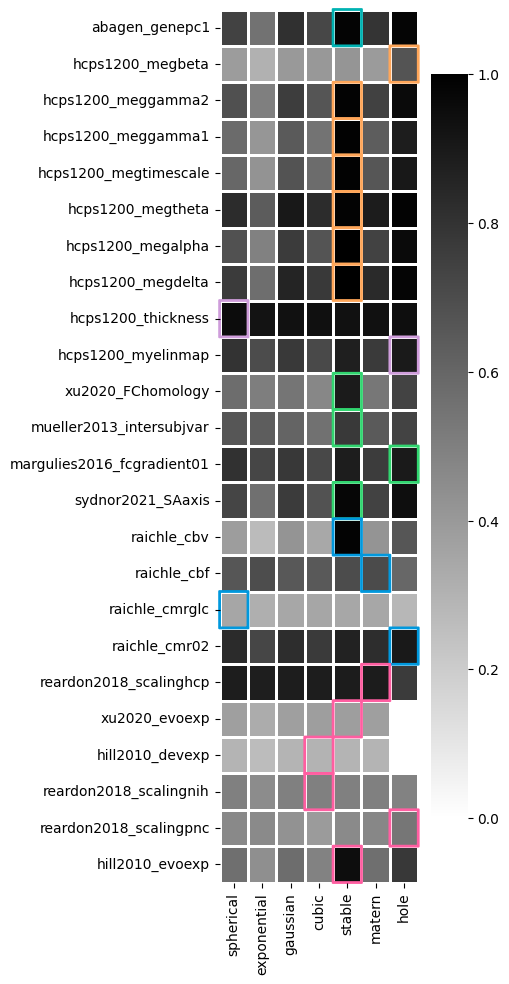

In [62]:
import seaborn as sns
from matplotlib.patches import FancyBboxPatch
data = pd.DataFrame(matrix)
data.columns = maptags
fig, ax = plt.subplots(figsize = (5,10))
data = data[mapnames]
sns.heatmap(data.T, yticklabels = mapnames, \
            linewidth = 2, linecolor = 'w', xticklabels = skgstat_mdls.keys(), vmin =0, vmax = 1, cmap = 'gist_yarg', ax=ax)

row_labels = []

for maptag in mapnames:
    col_label = maptag
    row_label = data[maptag].sort_values(ascending = False).index[0]
    row_labels.append(row_label)


    j = data.index.get_loc(row_label)
    i = data.columns.get_loc(col_label)
    
    #ax.add_patch(
    #    plt.Rectangle((j, i), 1, 1, fill=False, edgecolor="dimgray", linewidth=2)
    #)
    
    ax.add_patch(
        FancyBboxPatch(
            (j, i), 1, 1,
            boxstyle="round,pad=0.0001",
            linewidth=2,
            edgecolor=extended_cpal[maptag],
            facecolor="none", clip_on=False
        ))
    

plt.tight_layout()
plt.savefig(projdir + "/figs/rev_figs4_neuromaps_fit_vario.svg")

In [57]:
mdlnames = ['spherical', 'exponential', 'gaussian', 'cubic', 'stable', 'matern', 'hole']
show_models = [ mdlnames[ row_label ] for row_label in row_labels ]

In [58]:
show_models

['stable',
 'hole',
 'stable',
 'stable',
 'stable',
 'stable',
 'stable',
 'stable',
 'spherical',
 'hole',
 'stable',
 'stable',
 'hole',
 'stable',
 'stable',
 'matern',
 'spherical',
 'hole',
 'matern',
 'stable',
 'cubic',
 'cubic',
 'hole',
 'stable']

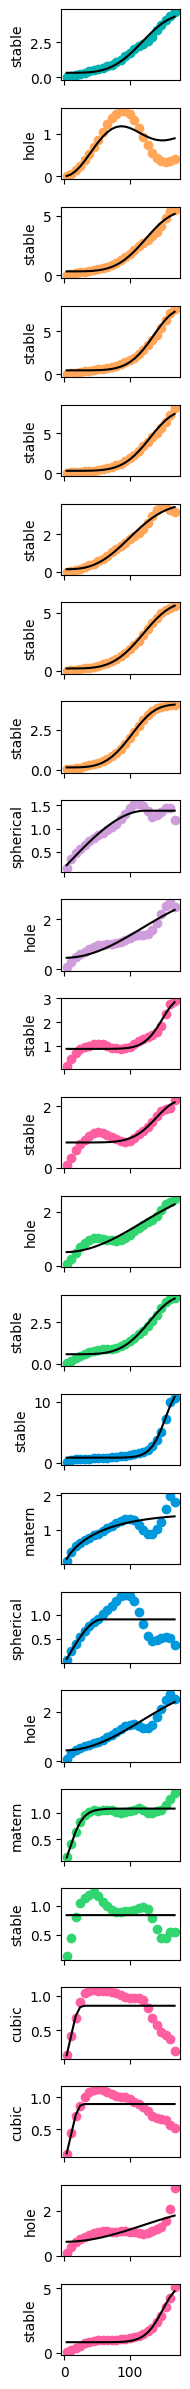

In [59]:
import matplotlib.pyplot as plt
import skgstat as skg
from scipy.optimize import curve_fit
from sklearn.metrics import r2_score
from interpmodules import metrics

fig, axs = plt.subplots(24, 1, figsize = (2,24), sharex=True)

for mi, mapname in enumerate(maptags):
    ev = all_ev[:,mi]
    nh = 25
    
    p0 = {3: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh],
              4: [np.max(h), np.nanmax(ev), np.nanmax(ev)/nh, ev[0]]
             }

    mapvals = zscore(src_pvdata[mapname])
    bounds = {3: ([0.00001]*3, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals))]),
    4: ([0.00001]*4, [np.max(Dist), semivariance(np.nanmax(mapvals), np.nanmin(mapvals)),
                        semivariance(np.nanmax(mapvals), np.nanmin(mapvals)), 100])}
    
    cof = None; cov = None
    
    gof = {}
        
    axs[mi].scatter(h, ev, color = extended_cpal[mapname])

    model = show_models[mi]
    if model in ['stable', 'matern']:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = bounds[4][1], bounds = bounds[4], maxfev=1000)
    
    else:
        cof, cov = curve_fit(skgstat_mdls[model], h, ev, method = 'trf', p0 = bounds[3][1], bounds = bounds[3], maxfev=1000)

    v_pred = skgstat_mdls[model](h, *cof)
    x_s = np.linspace(h.min(), h.max())
    axs[mi].plot(h, v_pred, color = 'k')
    mae = np.mean(metrics.metric(v_pred, ev, 'residual'))
    gof[model] = mae
    axs[mi].set_ylabel(model)
plt.tight_layout()
plt.savefig(projdir + "/figs/rev_figs4_neuromaps_little_variograms.svg")